In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
DATA_PATH = Path("../Data/Cleaned/Nepal_Online_Payment_System.csv")

df = pd.read_csv(DATA_PATH)
df["period_end"] = pd.to_datetime(df["period_end"])

In [4]:
df.shape

(645, 11)

### How much transaction activity is happening each month across all payment instruments?

In [5]:
monthly_totals = (
    df.groupby("period_end")
    .agg(
        total_txn_count=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum")
    )
    .sort_index()
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million
period_end,,
2023-07-01,100916114,5156481
2023-08-01,90886739,3985007
2023-09-01,95836096,3229087
2023-10-01,96256655,4073231
2023-11-01,82548409,3206725
2023-12-01,89227481,3733385
2024-01-01,93750989,3883287
2024-02-01,99192199,4051320
2024-03-01,96053423,4684595


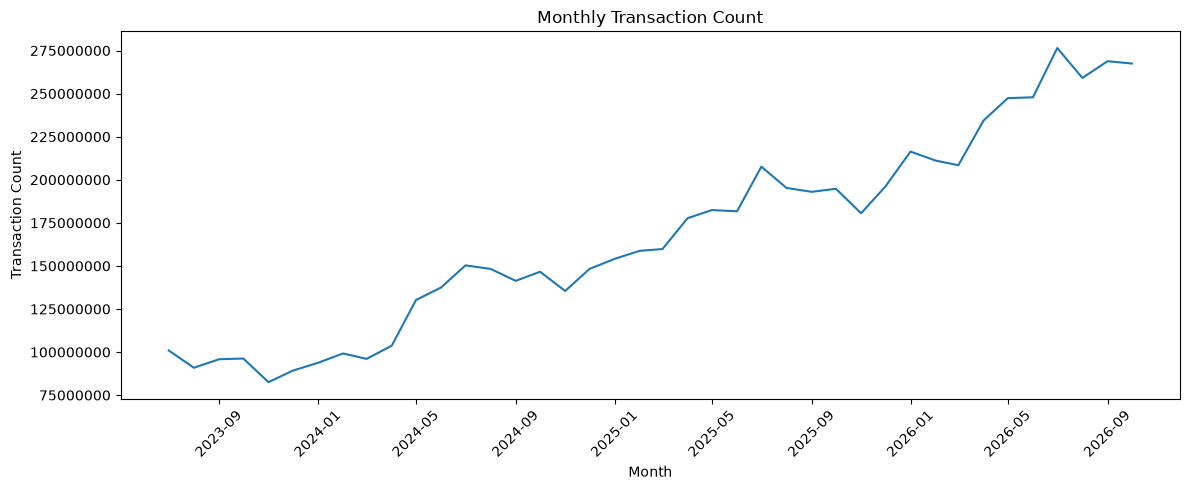

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["total_txn_count"]
)

plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Transaction Count")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

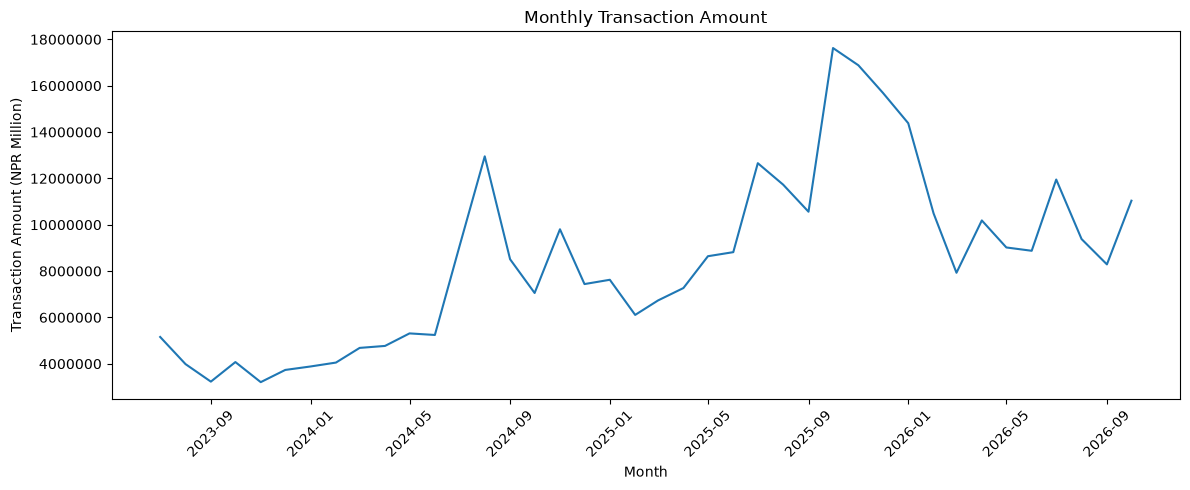

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["total_txn_amount_npr_million"]
)

plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Transaction Amount (NPR Million)")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

In [8]:
monthly_totals["avg_transaction_value_npr"] = (
    monthly_totals["total_txn_amount_npr_million"] * 1_000_000
    / monthly_totals["total_txn_count"]
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr
period_end,,,
2023-07-01,100916114,5156481,51096.71
2023-08-01,90886739,3985007,43845.86
2023-09-01,95836096,3229087,33693.85
2023-10-01,96256655,4073231,42316.36
2023-11-01,82548409,3206725,38846.60
2023-12-01,89227481,3733385,41841.20
2024-01-01,93750989,3883287,41421.29
2024-02-01,99192199,4051320,40843.13
2024-03-01,96053423,4684595,48770.72


### Observations:
1. Monthly transaction count increased substantially over the reporting period.
2. Monthly transaction amount also increased, although not consistently.
3. Average transaction value fluctuated, rather than increasing continuously.

### How much did transaction activity increase or decrease compared with the previous month?

In [9]:
monthly_totals["count_mom_growth_pct"] = (
    monthly_totals["total_txn_count"].pct_change() * 100
)

monthly_totals["amount_mom_growth_pct"] = (
    monthly_totals["total_txn_amount_npr_million"].pct_change() * 100
)

display(monthly_totals.round(2))

,total_txn_count,total_txn_amount_npr_million,avg_transaction_value_npr,count_mom_growth_pct,amount_mom_growth_pct
period_end,,,,,
2023-07-01,100916114,5156481,51096.71,NaN,NaN
2023-08-01,90886739,3985007,43845.86,-9.94,-22.72
2023-09-01,95836096,3229087,33693.85,5.45,-18.97
2023-10-01,96256655,4073231,42316.36,0.44,26.14
2023-11-01,82548409,3206725,38846.60,-14.24,-21.27
2023-12-01,89227481,3733385,41841.20,8.09,16.42
2024-01-01,93750989,3883287,41421.29,5.07,4.02
2024-02-01,99192199,4051320,40843.13,5.80,4.33
2024-03-01,96053423,4684595,48770.72,-3.16,15.63


### Key observations
Transaction count growth
- Highest growth: +25.61% in May 2024.
- Largest decline: -14.24% in November 2023.
- Transaction count generally shows an upward trend over the longer period.

Transaction amount growth
- Highest growth: +72.78% in July 2024.
- Largest decline: -34.29% in September 2024.
- Transaction amount fluctuates much more than transaction count.

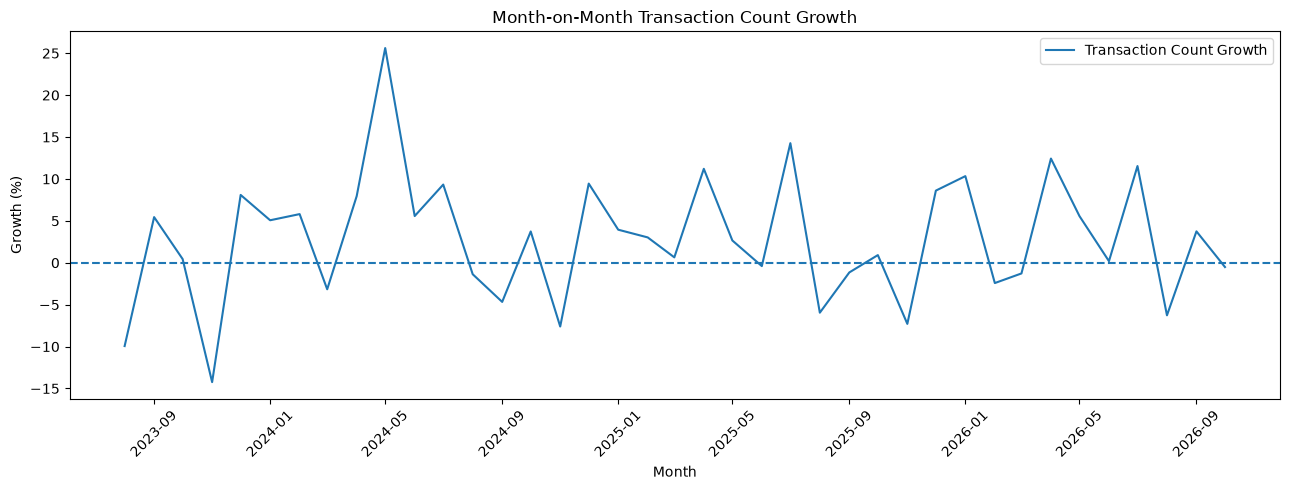

In [10]:
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["count_mom_growth_pct"],
    label="Transaction Count Growth"
)

plt.axhline(y=0, linestyle="--")

plt.title("Month-on-Month Transaction Count Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

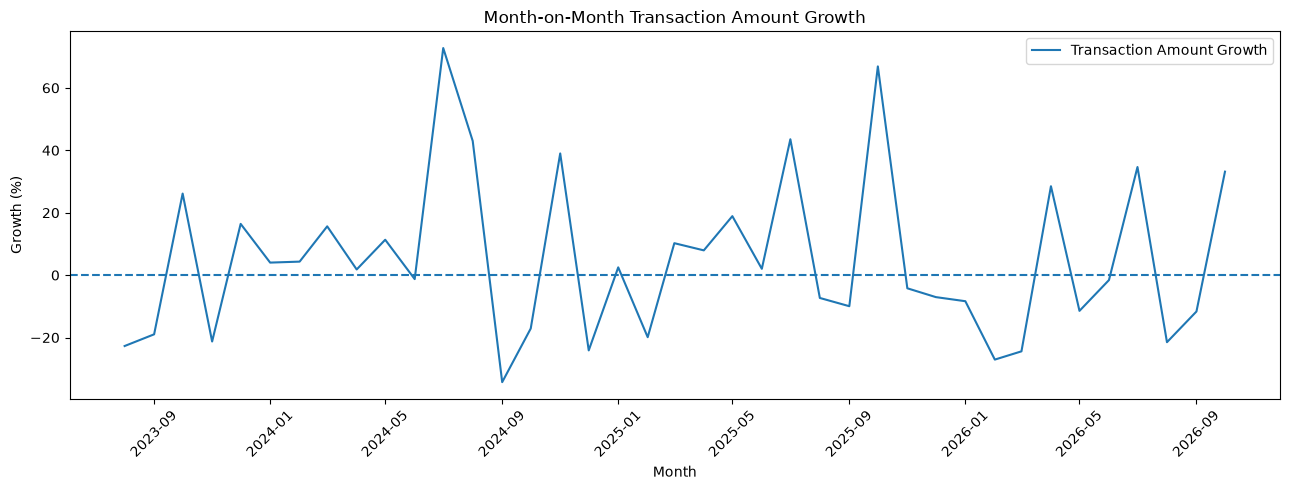

In [11]:
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_totals.index,
    monthly_totals["amount_mom_growth_pct"],
    label="Transaction Amount Growth"
)

plt.axhline(y=0, linestyle="--")

plt.title("Month-on-Month Transaction Amount Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
df[["bs_year", "bs_month"]].drop_duplicates().sort_values(
    ["bs_year", "bs_month"]
).head(20)

,bs_year,bs_month
0,2080,Asar
44,2080,Asoj
30,2080,Bhadau
128,2080,Chaitra
114,2080,Falgun
58,2080,Kartik
100,2080,Magh
72,2080,Mangsir
86,2080,Pus
16,2080,Saun
